EDA

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image 
%pip install seaborn
import seaborn as sns
import random 

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


--- ITSD Data Successfully Loaded ---
                     class_name  width  height
0  ALL_MOTOR_VEHICLE_PROHIBITED    218     225
1  ALL_MOTOR_VEHICLE_PROHIBITED    245     238
2  ALL_MOTOR_VEHICLE_PROHIBITED    233     225
3  ALL_MOTOR_VEHICLE_PROHIBITED    146     150
4  ALL_MOTOR_VEHICLE_PROHIBITED    263     265

Total Indian Test Images Found: 1288
Total Unique Indian Classes Found: 85


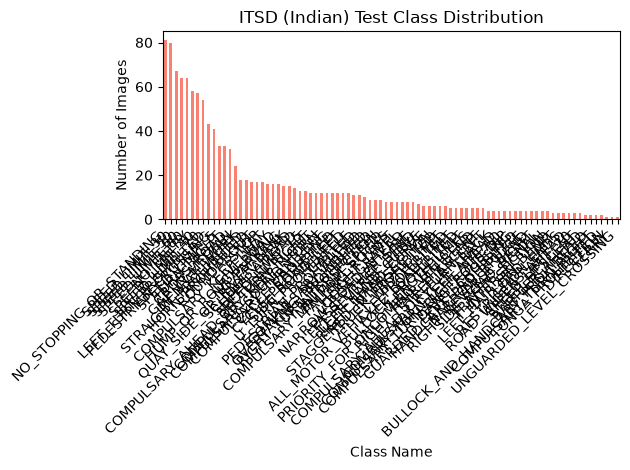

In [6]:
ITSD_TEST_DIR = r"D:\Intelligent Traffic Sign Classification System (Explainable ADAS)\Datasets\ITSD\test"

# 2. Programmatically build a metadata list by scanning folders
data = []

if os.path.exists(ITSD_TEST_DIR):
    for class_name in os.listdir(ITSD_TEST_DIR):
        class_folder = os.path.join(ITSD_TEST_DIR, class_name)
        
        # Ensure we are reading directories, not loose files
        if os.path.isdir(class_folder):
            for img_name in os.listdir(class_folder):
                img_path = os.path.join(class_folder, img_name)
                
                try:
                    with Image.open(img_path) as img:
                        width, height = img.size
                    
                    data.append({
                        "class_name": class_name,
                        "width": width,
                        "height": height
                    })
                except Exception as e:
                    # Skips system files or corrupted images if any exist
                    continue

    # Convert to standard Pandas DataFrame for analysis
    df_itsd = pd.DataFrame(data)
    print("--- ITSD Data Successfully Loaded ---")
    print(df_itsd.head())
    
    # 3. Print Summary Stats
    print(f"\nTotal Indian Test Images Found: {len(df_itsd)}")
    print(f"Total Unique Indian Classes Found: {df_itsd['class_name'].nunique()}")

    # 4. Plot Indian Class Distribution
    df_itsd['class_name'].value_counts().plot(kind='bar', color='salmon')
    plt.title("ITSD (Indian) Test Class Distribution")
    plt.xlabel("Class Name")
    plt.ylabel("Number of Images")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

else:
    print(f"Error: The path {ITSD_TEST_DIR} does not exist. Double check your folder structure layout!")


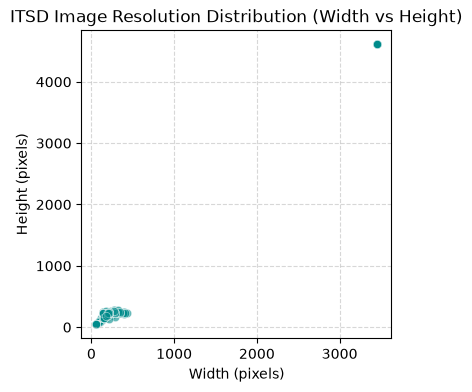

Minimum Dimensions: 50x44
Maximum Dimensions: 3456x4608


In [7]:

plt.figure(figsize=(4, 4))
sns.scatterplot(data=df_itsd, x='width', y='height', alpha=0.6, color='darkcyan')
plt.title("ITSD Image Resolution Distribution (Width vs Height)")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Print out the exact min/max ranges
print(f"Minimum Dimensions: {df_itsd['width'].min()}x{df_itsd['height'].min()}")
print(f"Maximum Dimensions: {df_itsd['width'].max()}x{df_itsd['height'].max()}")

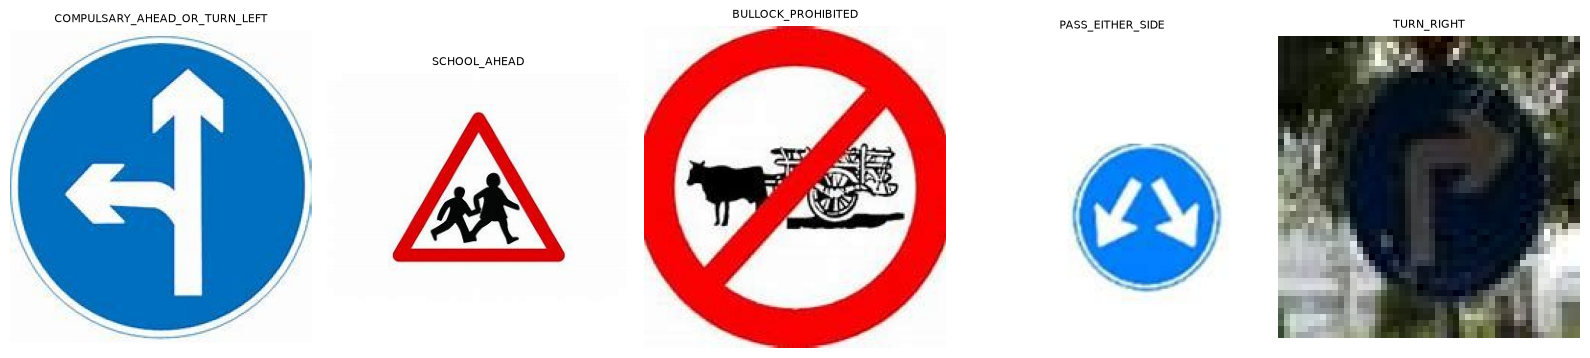

In [8]:

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
unique_classes = df_itsd['class_name'].unique()
random_classes = random.sample(list(unique_classes), 5)

for i, class_name in enumerate(random_classes):
    class_path = os.path.join(ITSD_TEST_DIR, class_name)
    all_imgs = os.listdir(class_path)
    random_img_name = random.choice(all_imgs)
    
    img_path = os.path.join(class_path, random_img_name)
    img = Image.open(img_path)
    
    axes[i].imshow(img)
    axes[i].set_title(class_name, fontsize=8, wrap=True)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [10]:
import json
from pathlib import Path
# Prefer the dataset mapping if it already exists; otherwise build it from the class folders
if "train_dataset" in globals() and hasattr(train_dataset, "class_to_idx"):
    class_to_idx = train_dataset.class_to_idx
else:
    class_to_idx = {
        class_name: idx
        for idx, class_name in enumerate(
            sorted([p.name for p in Path(ITSD_TEST_DIR).iterdir() if p.is_dir()])
        )
    }

with open("classes_indian.json", "w", encoding="utf-8") as f:
    json.dump(class_to_idx, f, indent=2)